# 🏢 Building Segmentation with SAM - Simple & Reliable

## The Problem with Previous Versions
They assumed windows are "cooler" (purple/blue). But in YOUR thermal image:
- **Windows = YELLOW (warm)** - showing interior heat through glass
- **Walls = ORANGE** - exterior surface temperature

## This Version's Approach
1. You select a few example windows manually
2. SAM segments them precisely  
3. We find ALL similar regions by **shape/size only** (no color assumptions)
4. Building = everything that's not a window

**This works regardless of thermal colormap!**

## 1. Setup

In [1]:
!pip install -q git+https://github.com/facebookresearch/segment-anything.git
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import files
from segment_anything import sam_model_registry, SamPredictor, SamAutomaticMaskGenerator
import torch

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"✅ Using: {device}")

# Load SAM
sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth")
sam.to(device)
predictor = SamPredictor(sam)
print("✅ SAM ready!")

  Preparing metadata (setup.py) ... done
✅ Using: cpu
✅ SAM ready!


## 2. Upload Image

Saving IRX_2927.JPG to IRX_2927.JPG
📐 Image: 640 x 512


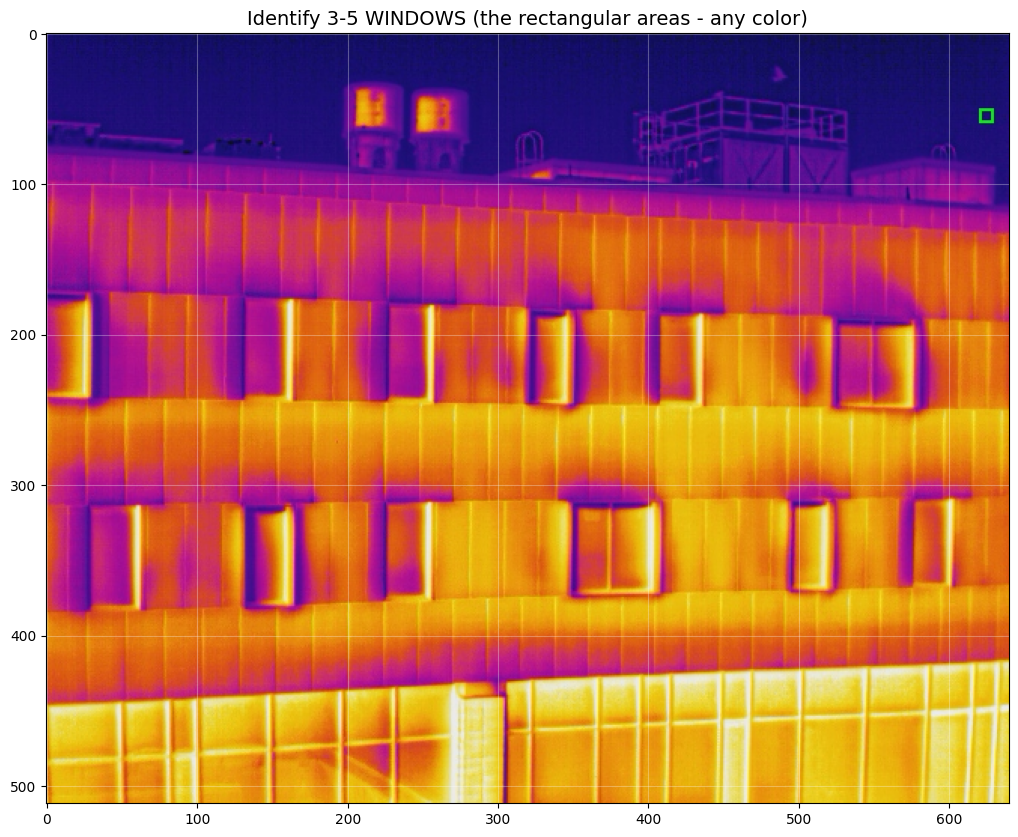


👆 Look at the image and identify rectangular WINDOW areas.
   Note their coordinates: [x_left, y_top, x_right, y_bottom]


In [2]:
uploaded = files.upload()
IMAGE_PATH = list(uploaded.keys())[0]

image_bgr = cv2.imread(IMAGE_PATH)
rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
h, w = gray.shape

print(f"📐 Image: {w} x {h}")

# Show with coordinates
fig, ax = plt.subplots(figsize=(14, 10))
ax.imshow(rgb)
ax.set_title('Identify 3-5 WINDOWS (the rectangular areas - any color)', fontsize=14)
ax.grid(True, alpha=0.3, color='white')
plt.show()

print("\n👆 Look at the image and identify rectangular WINDOW areas.")
print("   Note their coordinates: [x_left, y_top, x_right, y_bottom]")

## 3. ✏️ Define Your Window Boxes

**Select 3-5 windows from DIFFERENT rows/areas of the building.**

The windows in your image are the **yellow rectangular areas** on the facade.

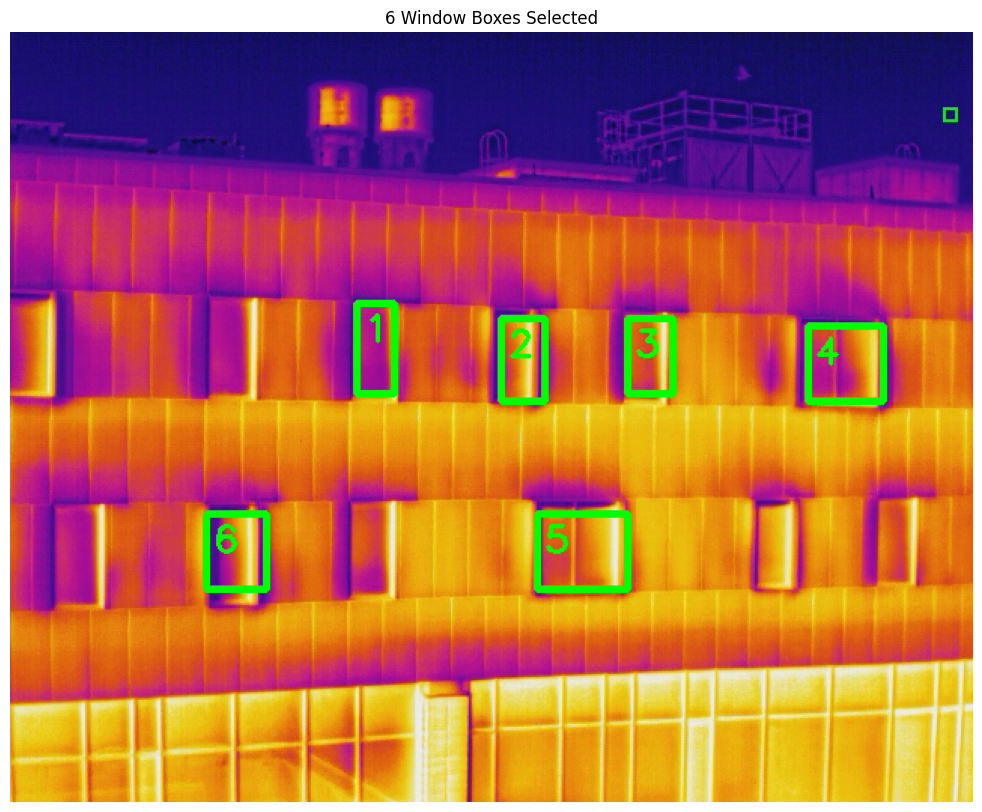


✅ If boxes look correct, continue to next cell.
❌ If wrong, edit WINDOW_BOXES above and re-run.


In [3]:
# =============================================
# 👇 EDIT THESE FOR YOUR IMAGE 👇
# Format: [x_left, y_top, x_right, y_bottom]
# Select the YELLOW RECTANGULAR windows!
# =============================================

WINDOW_BOXES = [
     # Row 1 windows (upper windows on building)
    [230, 180, 255, 240],   # Window 1
    [326, 190, 355, 245],   # Window 2
    [410, 190, 440, 240],   # Window 3
    [530, 195, 580, 245],   # Third window

    # Row 2 windows (lower windows)
    [350, 320, 410, 370],   # Lower left window
    [130, 320, 170, 370],   # Lower middle window
]

# =============================================

# Preview
vis = rgb.copy()
for i, (x0, y0, x1, y1) in enumerate(WINDOW_BOXES):
    cv2.rectangle(vis, (x0, y0), (x1, y1), (0, 255, 0), 3)
    cv2.putText(vis, str(i+1), (x0+5, y0+25), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

plt.figure(figsize=(14, 10))
plt.imshow(vis)
plt.title(f'{len(WINDOW_BOXES)} Window Boxes Selected')
plt.axis('off')
plt.show()

print("\n✅ If boxes look correct, continue to next cell.")
print("❌ If wrong, edit WINDOW_BOXES above and re-run.")

## 4. Segment Seed Windows with SAM

In [4]:
predictor.set_image(rgb)

seed_masks = []
seed_features = []

print("Segmenting seed windows...")
for i, box in enumerate(WINDOW_BOXES):
    masks, scores, _ = predictor.predict(
        box=np.array(box)[None, :],
        multimask_output=True
    )

    best_idx = np.argmax(scores)
    mask = masks[best_idx]
    seed_masks.append(mask)

    # Calculate features (SIZE and SHAPE only - no color!)
    area = np.sum(mask)
    coords = np.where(mask)
    if len(coords[0]) > 0:
        bbox_h = coords[0].max() - coords[0].min()
        bbox_w = coords[1].max() - coords[1].min()
        aspect = bbox_w / max(bbox_h, 1)
        seed_features.append({'area': area, 'width': bbox_w, 'height': bbox_h, 'aspect': aspect})

    print(f"  Window {i+1}: {area:,} pixels, {bbox_w}x{bbox_h}, aspect={aspect:.2f}")

print(f"\n✅ Segmented {len(seed_masks)} seed windows")

Segmenting seed windows...
  Window 1: 1,453 pixels, 23x61, aspect=0.38
  Window 2: 1,527 pixels, 26x62, aspect=0.42
  Window 3: 1,642 pixels, 28x58, aspect=0.48
  Window 4: 2,772 pixels, 50x55, aspect=0.91
  Window 5: 3,412 pixels, 57x61, aspect=0.93
  Window 6: 2,210 pixels, 33x67, aspect=0.49

✅ Segmented 6 seed windows


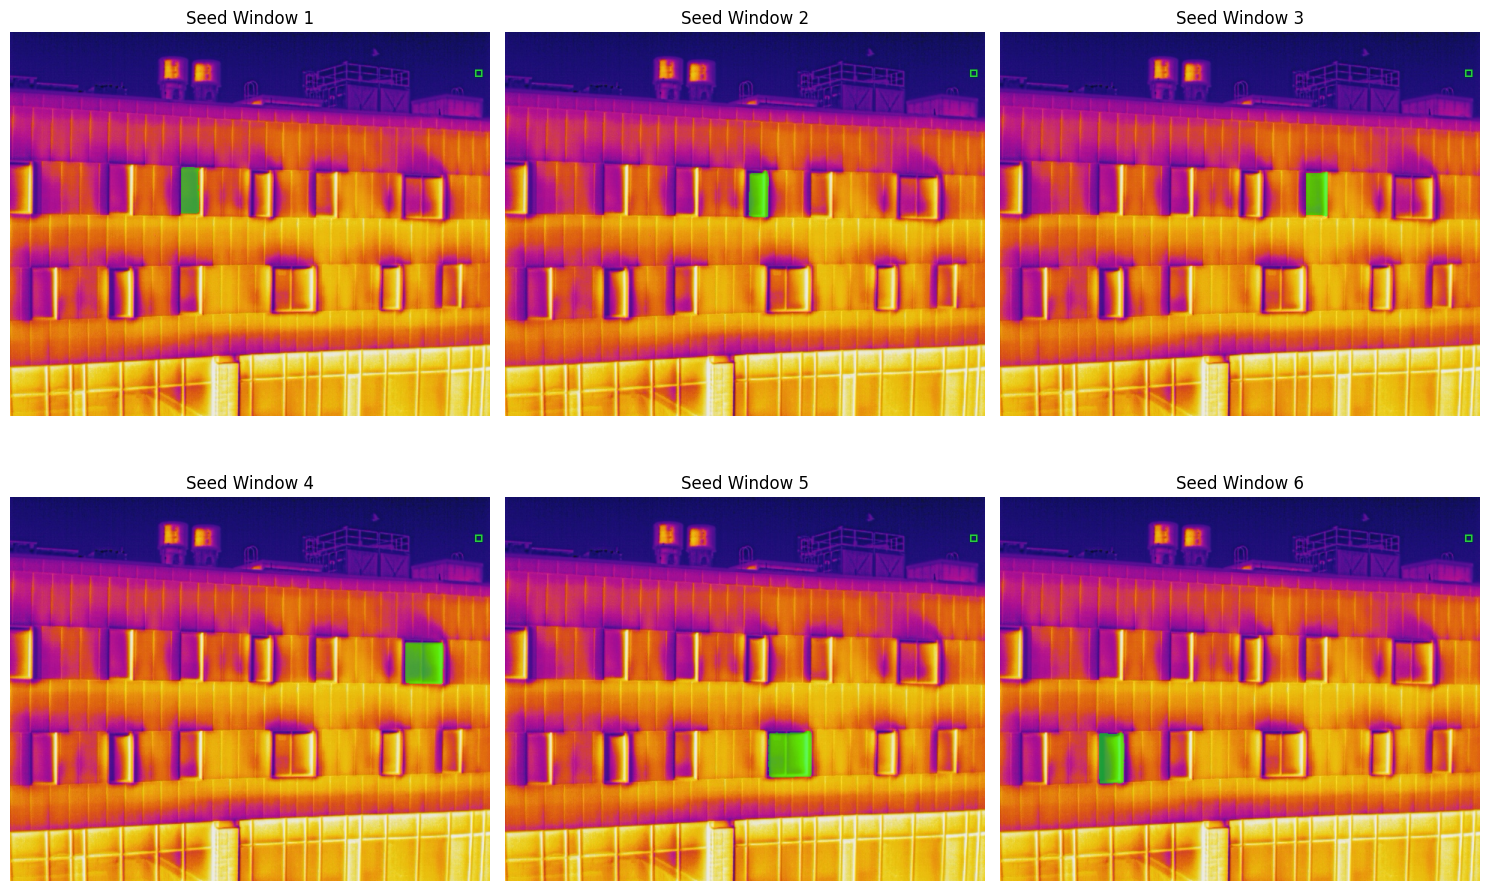

In [5]:
# Show seed masks
n_seeds = len(seed_masks)
cols = min(n_seeds, 3)
rows = (n_seeds + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 5*rows))
if n_seeds == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for i, mask in enumerate(seed_masks):
    overlay = rgb.copy()
    overlay[mask] = overlay[mask] * 0.4 + np.array([0, 255, 0]) * 0.6
    axes[i].imshow(overlay.astype(np.uint8))
    axes[i].set_title(f'Seed Window {i+1}')
    axes[i].axis('off')

for i in range(n_seeds, len(axes)):
    axes[i].axis('off')

plt.tight_layout()
plt.show()

## 5. Calculate Average Window Size

In [6]:
# Average window characteristics (SIZE/SHAPE only)
avg_area = np.mean([f['area'] for f in seed_features])
avg_area_std = np.std([f['area'] for f in seed_features])
avg_width = np.mean([f['width'] for f in seed_features])
avg_height = np.mean([f['height'] for f in seed_features])
avg_aspect = np.mean([f['aspect'] for f in seed_features])

print("📊 Average Window Characteristics:")
print(f"  Area: {avg_area:,.0f} ± {avg_area_std:,.0f} pixels")
print(f"  Size: {avg_width:.0f} x {avg_height:.0f} pixels")
print(f"  Aspect ratio: {avg_aspect:.2f}")

# Define acceptable ranges
min_area = avg_area * 0.3
max_area = avg_area * 3.0
min_aspect = avg_aspect * 0.5
max_aspect = avg_aspect * 2.0

print(f"\n🎯 Will search for regions with:")
print(f"  Area: {min_area:,.0f} - {max_area:,.0f} pixels")
print(f"  Aspect: {min_aspect:.2f} - {max_aspect:.2f}")

📊 Average Window Characteristics:
  Area: 2,169 ± 720 pixels
  Size: 36 x 61 pixels
  Aspect ratio: 0.60

🎯 Will search for regions with:
  Area: 651 - 6,508 pixels
  Aspect: 0.30 - 1.21


## 6. Generate ALL Masks with SAM

In [7]:
# Generate all possible masks
mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=32,
    pred_iou_thresh=0.88,
    stability_score_thresh=0.92,
    min_mask_region_area=int(min_area * 0.5),  # Filter tiny regions
)

print("Generating all masks (this takes ~30 seconds)...")
all_masks = mask_generator.generate(rgb)
print(f"✅ Generated {len(all_masks)} total masks")

Generating all masks (this takes ~30 seconds)...
✅ Generated 87 total masks


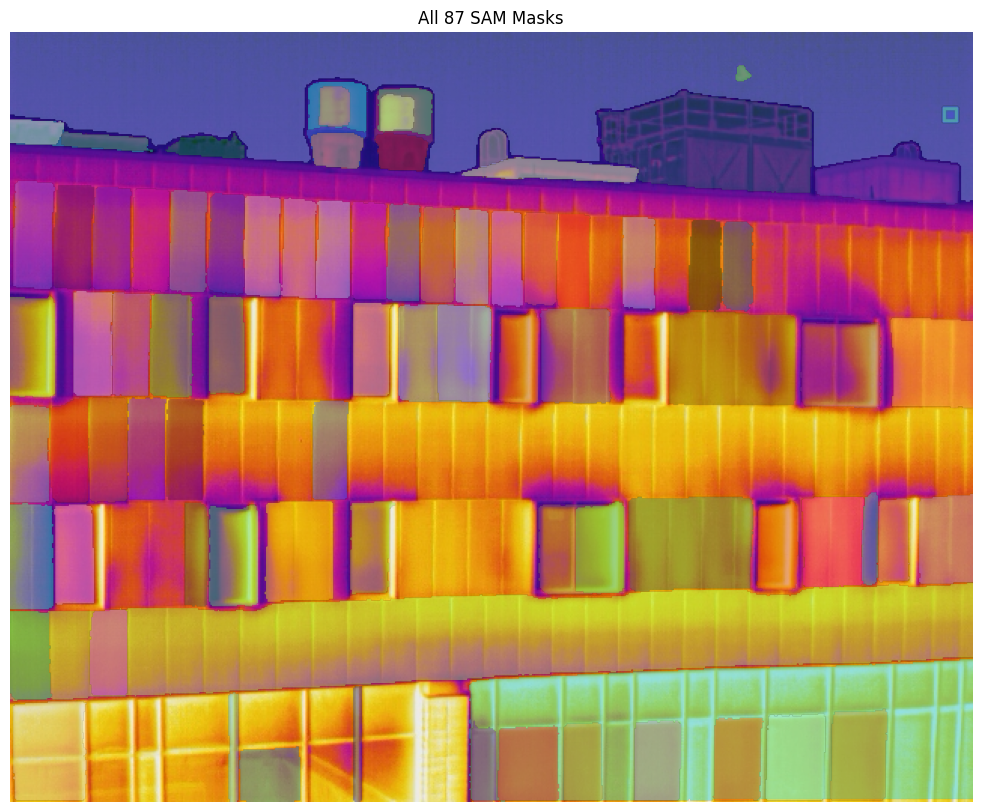

In [8]:
# Show all masks
plt.figure(figsize=(14, 10))
plt.imshow(rgb)

for mask_data in sorted(all_masks, key=lambda x: x['area'], reverse=True):
    m = mask_data['segmentation']
    color = np.random.random(3)
    colored_mask = np.zeros((*m.shape, 4))
    colored_mask[m] = [*color, 0.4]
    plt.imshow(colored_mask)

plt.title(f'All {len(all_masks)} SAM Masks')
plt.axis('off')
plt.show()

## 7. Filter for Window-Sized Regions

In [9]:
def get_mask_shape(mask):
    """Get shape features of a mask"""
    coords = np.where(mask)
    if len(coords[0]) == 0:
        return None

    y_min, y_max = coords[0].min(), coords[0].max()
    x_min, x_max = coords[1].min(), coords[1].max()

    height = y_max - y_min
    width = x_max - x_min
    area = np.sum(mask)
    aspect = width / max(height, 1)

    # Rectangularity (how much of bounding box is filled)
    bbox_area = height * width
    rectangularity = area / bbox_area if bbox_area > 0 else 0

    return {
        'area': area,
        'width': width,
        'height': height,
        'aspect': aspect,
        'rectangularity': rectangularity,
        'center_y': (y_min + y_max) / 2,
        'center_x': (x_min + x_max) / 2
    }

# Filter masks by SIZE and SHAPE (not color!)
window_candidates = []

for mask_data in all_masks:
    mask = mask_data['segmentation']
    shape = get_mask_shape(mask)

    if shape is None:
        continue

    # Check size
    if not (min_area < shape['area'] < max_area):
        continue

    # Check aspect ratio
    if not (min_aspect < shape['aspect'] < max_aspect):
        continue

    # Check rectangularity (windows should be fairly rectangular)
    if shape['rectangularity'] < 0.5:
        continue

    window_candidates.append({
        'mask': mask,
        'shape': shape,
        'score': mask_data['predicted_iou']
    })

print(f"✅ Found {len(window_candidates)} window-sized regions")

✅ Found 62 window-sized regions


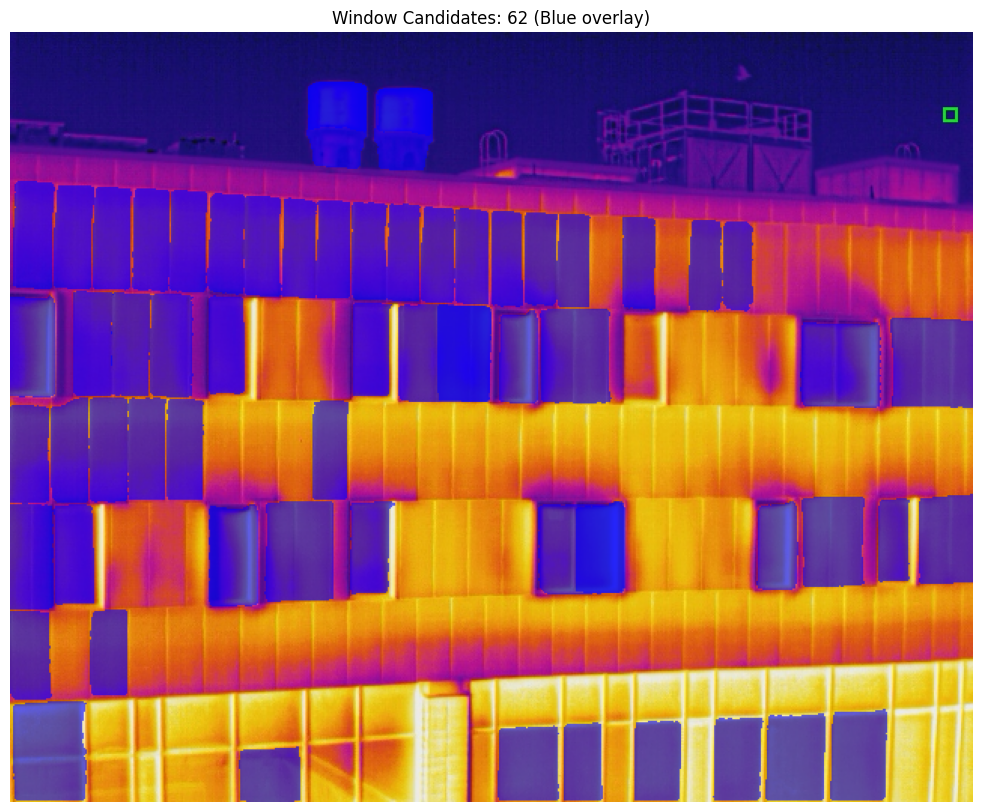


👆 These are all regions that MATCH the size/shape of your seed windows.
   If this includes non-windows, we'll adjust in the next step.


In [10]:
# Visualize candidates
vis = rgb.copy().astype(float)

for cand in window_candidates:
    mask = cand['mask']
    vis[mask] = vis[mask] * 0.4 + np.array([0, 0, 255]) * 0.6

plt.figure(figsize=(14, 10))
plt.imshow(vis.astype(np.uint8))
plt.title(f'Window Candidates: {len(window_candidates)} (Blue overlay)')
plt.axis('off')
plt.show()

print("\n👆 These are all regions that MATCH the size/shape of your seed windows.")
print("   If this includes non-windows, we'll adjust in the next step.")

## 8. 🎛️ Adjust Detection (If Needed)

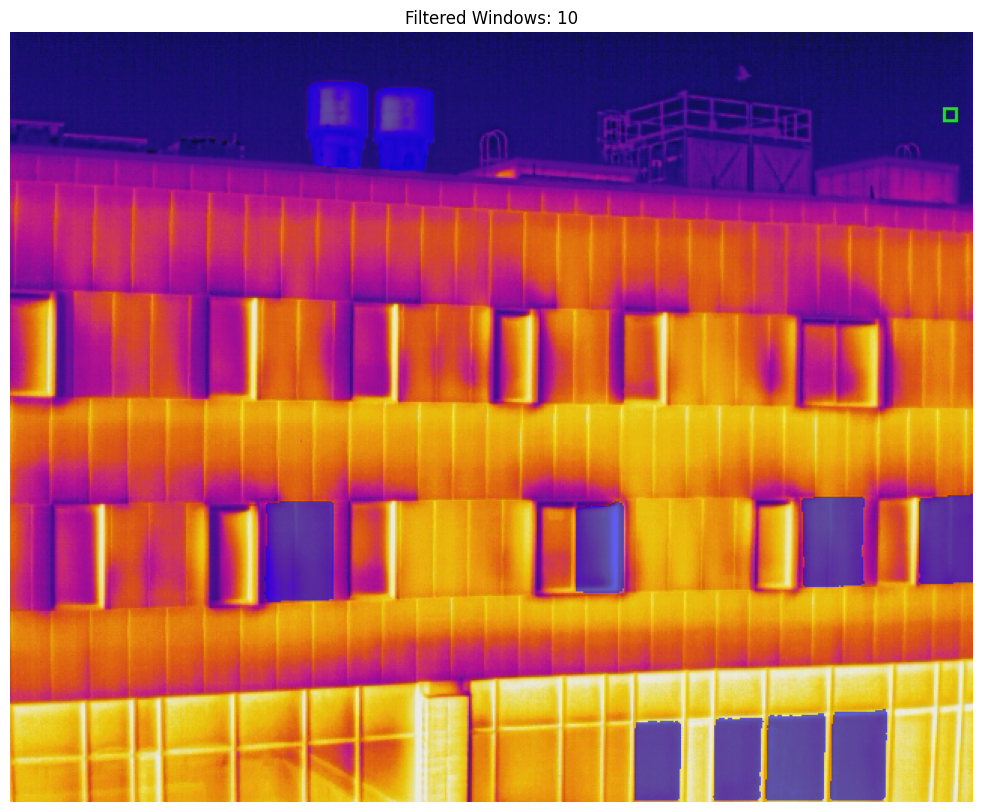


✅ 10 windows after filtering


In [17]:
#@title Adjust Window Detection { run: "auto" }

size_tolerance = 2.25  #@param {type:"slider", min:1.0, max:5.0, step:0.25}
aspect_tolerance = 1.25  #@param {type:"slider", min:1.0, max:3.0, step:0.25}
min_rectangularity = 0.6  #@param {type:"slider", min:0.3, max:0.8, step:0.05}
min_score = 0.9  #@param {type:"slider", min:0.7, max:0.95, step:0.05}

# Re-filter with new parameters
adj_min_area = avg_area / size_tolerance
adj_max_area = avg_area * size_tolerance
adj_min_aspect = avg_aspect / aspect_tolerance
adj_max_aspect = avg_aspect * aspect_tolerance

filtered_windows = []

for mask_data in all_masks:
    mask = mask_data['segmentation']
    shape = get_mask_shape(mask)

    if shape is None:
        continue

    if not (adj_min_area < shape['area'] < adj_max_area):
        continue
    if not (adj_min_aspect < shape['aspect'] < adj_max_aspect):
        continue
    if shape['rectangularity'] < min_rectangularity:
        continue
    if mask_data['predicted_iou'] < min_score:
        continue

    filtered_windows.append(mask)

# Visualize
vis = rgb.copy().astype(float)
for mask in filtered_windows:
    vis[mask] = vis[mask] * 0.4 + np.array([0, 0, 255]) * 0.6

plt.figure(figsize=(14, 10))
plt.imshow(vis.astype(np.uint8))
plt.title(f'Filtered Windows: {len(filtered_windows)}')
plt.axis('off')
plt.show()

# Update candidates
window_candidates = [{'mask': m} for m in filtered_windows]
print(f"\n✅ {len(filtered_windows)} windows after filtering")

## 9. Create Final Masks

In [18]:
# Combine all window masks
window_mask = np.zeros((h, w), dtype=np.uint8)
for cand in window_candidates:
    window_mask[cand['mask']] = 255

# Building = NOT window
building_mask = np.ones((h, w), dtype=np.uint8) * 255
building_mask[window_mask > 0] = 0

print(f"📊 Final Segmentation:")
print(f"  Windows: {len(window_candidates)} detected")
print(f"  Window area: {np.sum(window_mask > 0):,} pixels ({np.sum(window_mask > 0)/window_mask.size*100:.1f}%)")
print(f"  Building area: {np.sum(building_mask > 0):,} pixels ({np.sum(building_mask > 0)/building_mask.size*100:.1f}%)")

📊 Final Segmentation:
  Windows: 10 detected
  Window area: 20,941 pixels (6.4%)
  Building area: 306,739 pixels (93.6%)


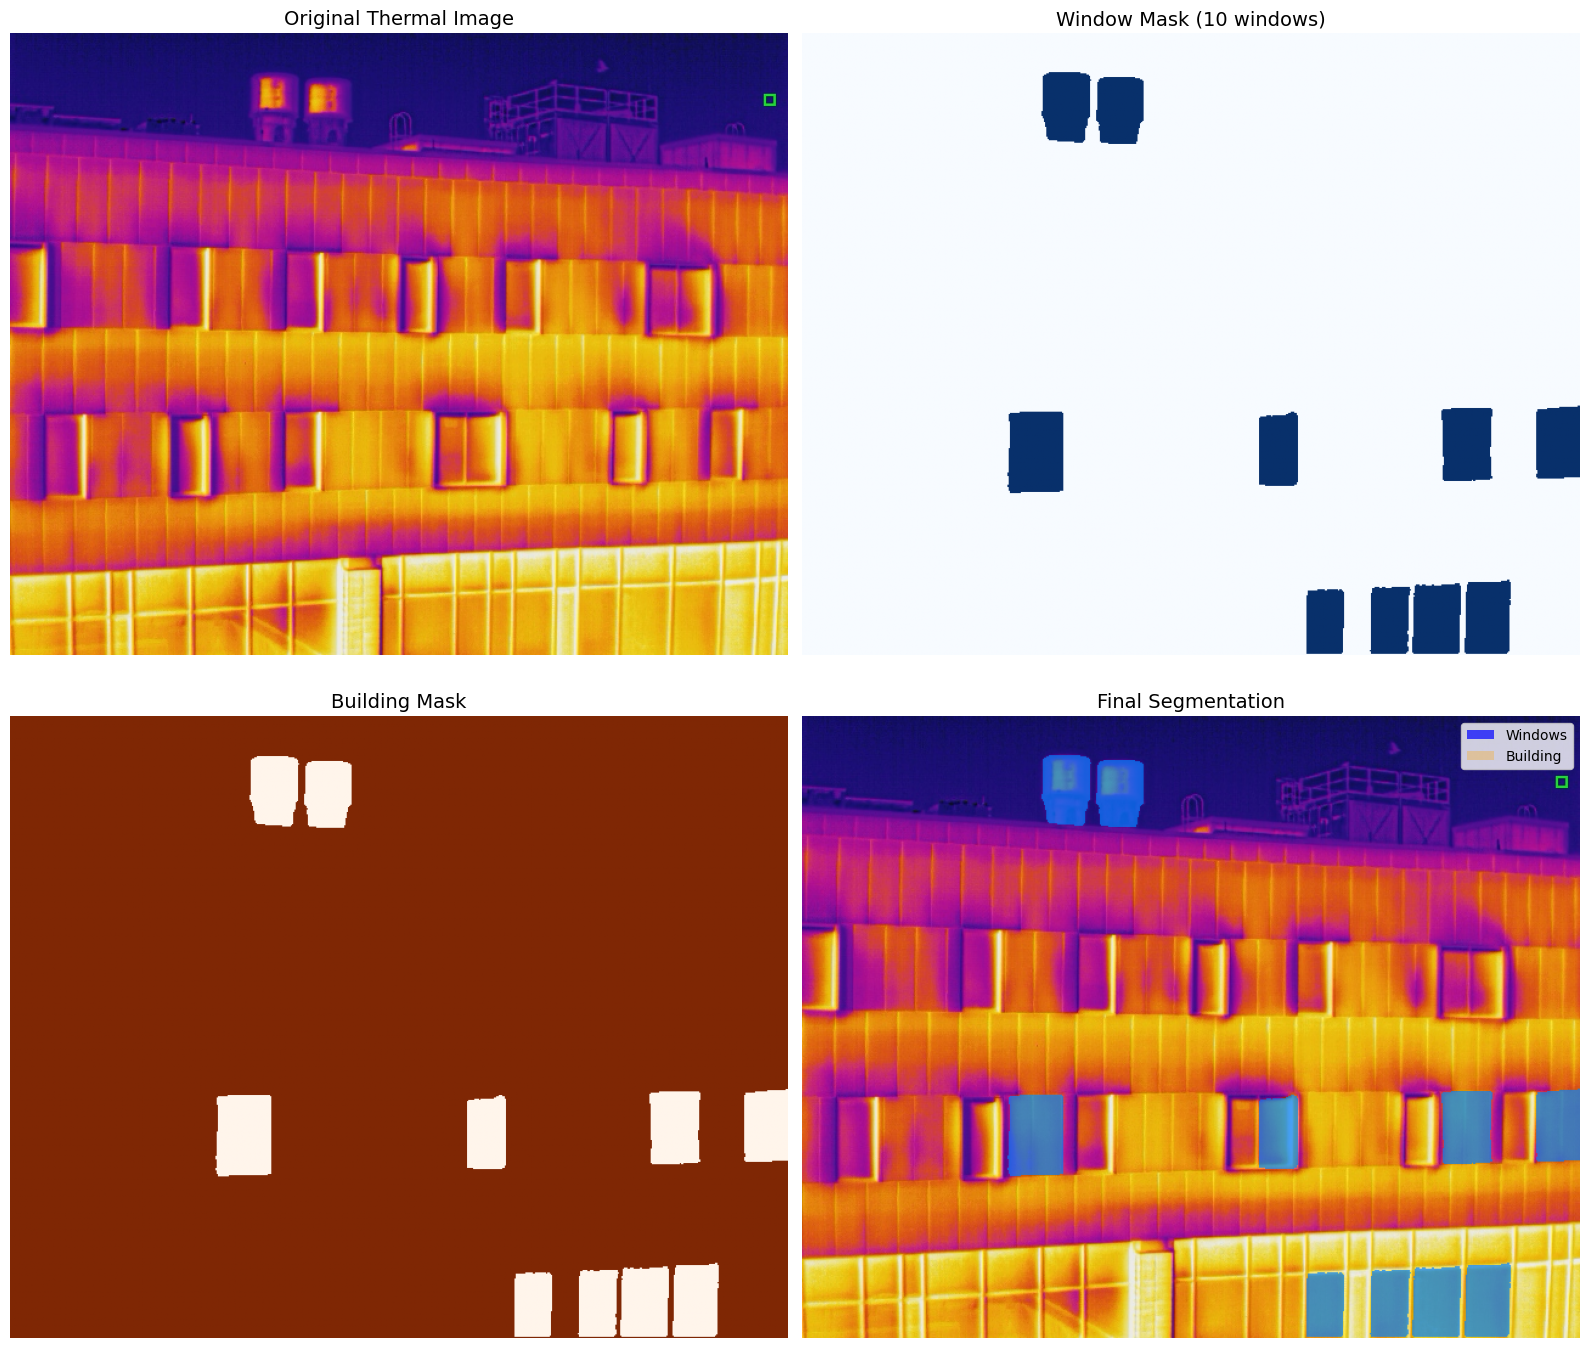

In [19]:
# Final visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# Original
axes[0,0].imshow(rgb)
axes[0,0].set_title('Original Thermal Image', fontsize=14)
axes[0,0].axis('off')

# Window mask
axes[0,1].imshow(window_mask, cmap='Blues')
axes[0,1].set_title(f'Window Mask ({len(window_candidates)} windows)', fontsize=14)
axes[0,1].axis('off')

# Building mask
axes[1,0].imshow(building_mask, cmap='Oranges')
axes[1,0].set_title('Building Mask', fontsize=14)
axes[1,0].axis('off')

# Overlay
overlay = rgb.copy().astype(float) / 255
overlay[window_mask > 0] = overlay[window_mask > 0] * 0.3 + np.array([0, 0.5, 1]) * 0.7

axes[1,1].imshow(overlay)
axes[1,1].set_title('Final Segmentation', fontsize=14)
axes[1,1].axis('off')

from matplotlib.patches import Patch
legend = [Patch(facecolor='blue', alpha=0.7, label='Windows'),
          Patch(facecolor='orange', alpha=0.3, label='Building')]
axes[1,1].legend(handles=legend, loc='upper right')

plt.tight_layout()
plt.savefig('segmentation_result.png', dpi=150)
plt.show()

## 10. 🌡️ Thermal Analysis (For Anomaly Detection)

This is the data you'll use for anomaly detection!

In [20]:
print("="*60)
print("🌡️ THERMAL ANALYSIS")
print("="*60)

# Window statistics
win_pixels = gray[window_mask > 0]
bld_pixels = gray[building_mask > 0]

print(f"\nWINDOWS ({len(window_candidates)} total):")
print(f"  Mean intensity: {np.mean(win_pixels):.1f}")
print(f"  Std deviation:  {np.std(win_pixels):.1f}")
print(f"  Range: {np.min(win_pixels)} - {np.max(win_pixels)}")

print(f"\nBUILDING (walls/roof):")
print(f"  Mean intensity: {np.mean(bld_pixels):.1f}")
print(f"  Std deviation:  {np.std(bld_pixels):.1f}")
print(f"  Range: {np.min(bld_pixels)} - {np.max(bld_pixels)}")

diff = np.mean(win_pixels) - np.mean(bld_pixels)
print(f"\n🔥 Windows are {abs(diff):.1f} units {'WARMER' if diff > 0 else 'COOLER'} than building")
print(f"   (This indicates heat {'loss through windows' if diff > 0 else 'retention'})")

🌡️ THERMAL ANALYSIS

WINDOWS (10 total):
  Mean intensity: 142.0
  Std deviation:  45.4
  Range: 29 - 236

BUILDING (walls/roof):
  Mean intensity: 113.9
  Std deviation:  55.4
  Range: 14 - 238

🔥 Windows are 28.2 units WARMER than building
   (This indicates heat loss through windows)


In [21]:
# Per-window analysis (for anomaly detection)
print("\n" + "="*60)
print("📊 PER-WINDOW THERMAL DATA")
print("="*60)

window_stats = []

for i, cand in enumerate(window_candidates):
    mask = cand['mask']
    pixels = gray[mask]

    stats = {
        'id': i + 1,
        'mean': np.mean(pixels),
        'std': np.std(pixels),
        'min': np.min(pixels),
        'max': np.max(pixels),
        'area': np.sum(mask)
    }
    window_stats.append(stats)

    print(f"Window {i+1:2d}: mean={stats['mean']:.1f}, std={stats['std']:.1f}, range=[{stats['min']}-{stats['max']}]")

# Find anomalies (windows significantly different from average)
mean_window_temp = np.mean([s['mean'] for s in window_stats])
std_window_temp = np.std([s['mean'] for s in window_stats])

print(f"\n🎯 Average window intensity: {mean_window_temp:.1f} ± {std_window_temp:.1f}")

anomalies = [s for s in window_stats if abs(s['mean'] - mean_window_temp) > 2 * std_window_temp]
if anomalies:
    print(f"\n⚠️ POTENTIAL ANOMALIES (>2σ from mean):")
    for a in anomalies:
        print(f"   Window {a['id']}: {a['mean']:.1f} (deviation: {a['mean'] - mean_window_temp:+.1f})")
else:
    print(f"\n✅ No obvious anomalies detected (all windows within 2σ)")


📊 PER-WINDOW THERMAL DATA
Window  1: mean=74.1, std=36.5, range=[29-182]
Window  2: mean=73.2, std=39.8, range=[32-192]
Window  3: mean=152.0, std=17.5, range=[98-200]
Window  4: mean=172.1, std=11.1, range=[143-227]
Window  5: mean=134.2, std=11.8, range=[86-169]
Window  6: mean=166.6, std=38.8, range=[60-236]
Window  7: mean=172.0, std=11.1, range=[154-232]
Window  8: mean=186.4, std=10.4, range=[161-233]
Window  9: mean=126.6, std=21.9, range=[54-179]
Window 10: mean=176.6, std=12.4, range=[154-228]

🎯 Average window intensity: 143.4 ± 39.1

✅ No obvious anomalies detected (all windows within 2σ)


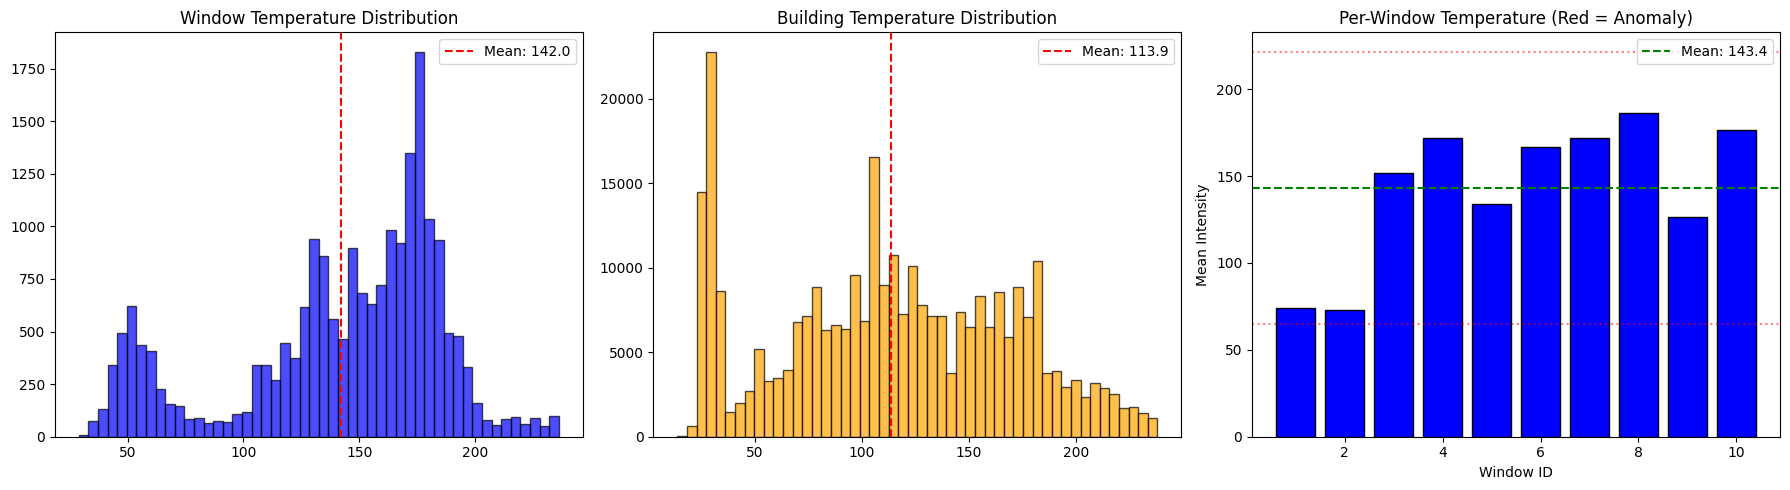

In [22]:
# Visualize temperature distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Window histogram
axes[0].hist(win_pixels, bins=50, color='blue', alpha=0.7, edgecolor='black')
axes[0].axvline(np.mean(win_pixels), color='red', linestyle='--', label=f'Mean: {np.mean(win_pixels):.1f}')
axes[0].set_title('Window Temperature Distribution')
axes[0].legend()

# Building histogram
axes[1].hist(bld_pixels, bins=50, color='orange', alpha=0.7, edgecolor='black')
axes[1].axvline(np.mean(bld_pixels), color='red', linestyle='--', label=f'Mean: {np.mean(bld_pixels):.1f}')
axes[1].set_title('Building Temperature Distribution')
axes[1].legend()

# Per-window mean comparison
window_means = [s['mean'] for s in window_stats]
colors = ['red' if abs(m - mean_window_temp) > 2*std_window_temp else 'blue' for m in window_means]
axes[2].bar(range(1, len(window_means)+1), window_means, color=colors, edgecolor='black')
axes[2].axhline(mean_window_temp, color='green', linestyle='--', label=f'Mean: {mean_window_temp:.1f}')
axes[2].axhline(mean_window_temp + 2*std_window_temp, color='red', linestyle=':', alpha=0.5)
axes[2].axhline(mean_window_temp - 2*std_window_temp, color='red', linestyle=':', alpha=0.5)
axes[2].set_xlabel('Window ID')
axes[2].set_ylabel('Mean Intensity')
axes[2].set_title('Per-Window Temperature (Red = Anomaly)')
axes[2].legend()

plt.tight_layout()
plt.show()

## 11. Export Results

In [23]:
import os

output_dir = 'segmentation_output'
os.makedirs(output_dir, exist_ok=True)

# Save masks
cv2.imwrite(f'{output_dir}/window_mask.png', window_mask)
cv2.imwrite(f'{output_dir}/building_mask.png', building_mask)

# Save individual window masks
for i, cand in enumerate(window_candidates):
    mask_img = (cand['mask'].astype(np.uint8)) * 255
    cv2.imwrite(f'{output_dir}/window_{i+1:02d}.png', mask_img)

# Save data
np.savez(f'{output_dir}/data.npz',
         image=rgb,
         gray=gray,
         window_mask=window_mask,
         building_mask=building_mask,
         window_stats=np.array([(s['id'], s['mean'], s['std'], s['min'], s['max'], s['area'])
                                 for s in window_stats]))

print(f"✅ Saved to {output_dir}/")
for f in sorted(os.listdir(output_dir)):
    print(f"  - {f}")

✅ Saved to segmentation_output/
  - building_mask.png
  - data.npz
  - window_01.png
  - window_02.png
  - window_03.png
  - window_04.png
  - window_05.png
  - window_06.png
  - window_07.png
  - window_08.png
  - window_09.png
  - window_10.png
  - window_mask.png


In [ ]:
# Download
!zip -r output.zip segmentation_output/
files.download('output.zip')
print("📥 Download started!")

---

## 📋 Summary

**This version works because:**
1. ✅ No color assumptions - works with ANY thermal colormap
2. ✅ Uses SIZE and SHAPE matching only
3. ✅ You teach it what a "window" looks like by example
4. ✅ SAM provides precise boundaries

**For your anomaly detection:**
- `window_stats` contains per-window thermal data
- Windows with intensity >2σ from mean are flagged as anomalies
- Use the individual window masks for detailed analysis

**Next steps for anomaly detection:**
1. Compare windows to building surroundings
2. Look for hot/cold spots within windows
3. Analyze temperature gradients at window edges (thermal bridges)